# Brain tumor segmentation (U-Net, ResNet-34) on LGG MRI

Run on **Kaggle** with the `mateuszbuda/lgg-mri-segmentation` dataset attached, a GPU enabled (T4/P100) and Internet on. Splits are by patient (74 / 14 / 22). Run cells top to bottom; training takes about 15 minutes and saves `best_unet.pt`.

In [5]:
!pip install -q segmentation-models-pytorch
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [6]:
# Fix random seeds so training and evaluation are reproducible
import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

In [7]:
!find /kaggle/input -maxdepth 3 | head -20

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/mateuszbuda
/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation


In [8]:
import glob, os
masks = sorted(glob.glob("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/**/*_mask.tif", recursive=True))
print(len(masks), "masks")   # expect ~3929
print(masks[0])


7858 masks
/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_10_mask.tif


In [9]:
ROOT = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
masks = sorted(glob.glob(f"{ROOT}/*/*_mask.tif"))
print(len(masks), "masks")   # expect 3929
print(len({os.path.basename(os.path.dirname(m)) for m in masks}), "patients")   # expect 110


3929 masks
110 patients


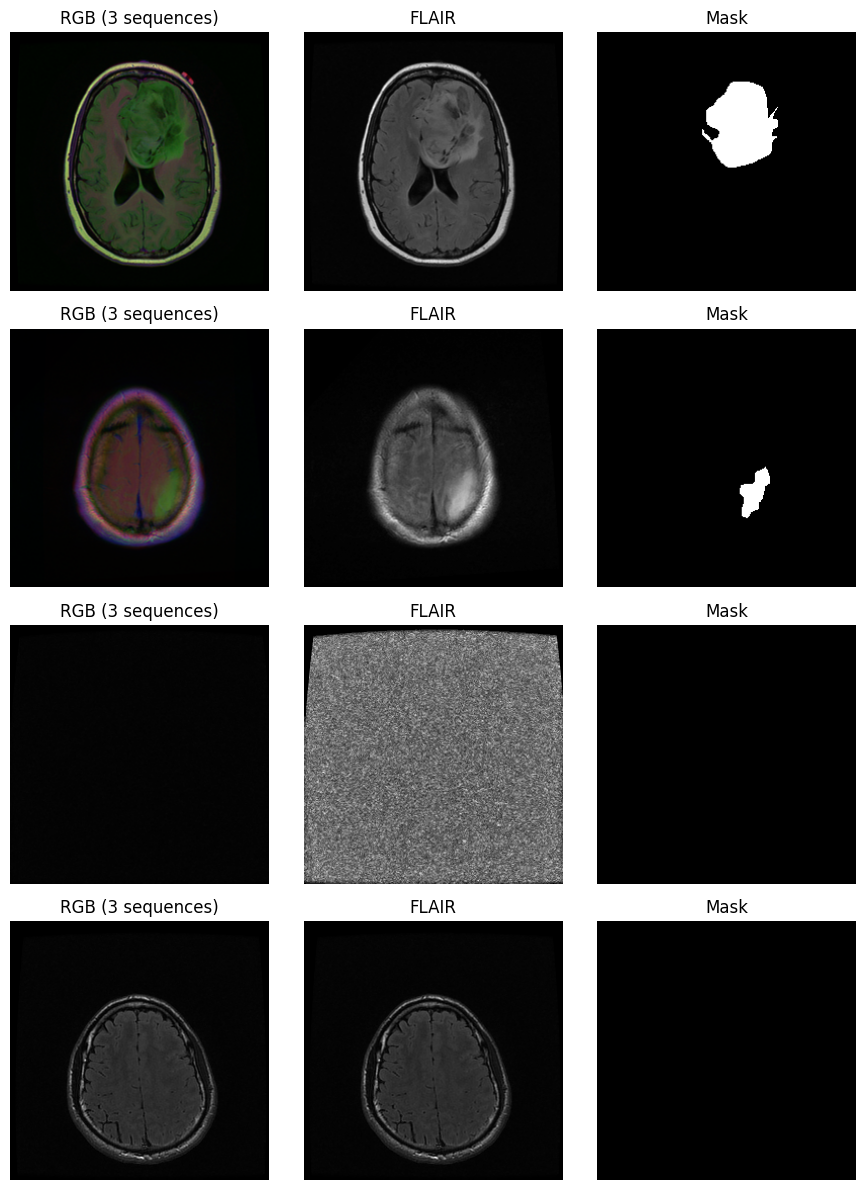

In [10]:
import numpy as np, matplotlib.pyplot as plt
from skimage.io import imread

picks = [masks[i] for i in np.random.RandomState(0).choice(len(masks), 4, replace=False)]
fig, ax = plt.subplots(4, 3, figsize=(9, 12))
for r, m in enumerate(picks):
    img, msk = imread(m.replace("_mask", "")), imread(m)
    ax[r, 0].imshow(img);                       ax[r, 0].set_title("RGB (3 sequences)")
    ax[r, 1].imshow(img[..., 1], cmap="gray");  ax[r, 1].set_title("FLAIR")
    ax[r, 2].imshow(msk, cmap="gray");          ax[r, 2].set_title("Mask")
    for a in ax[r]: a.axis("off")
plt.tight_layout()

In [11]:
import os, glob, numpy as np
from sklearn.model_selection import GroupShuffleSplit

ROOT = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
masks = sorted(glob.glob(f"{ROOT}/*/*_mask.tif"))
images = [m.replace("_mask", "") for m in masks]
patients = np.array([os.path.basename(os.path.dirname(m)) for m in masks])
masks, images = np.array(masks), np.array(images)

# 1) hold out 20% of patients for testing
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
trainval_idx, test_idx = next(gss.split(images, groups=patients))

# 2) from the rest, hold out ~15% of patients for validation
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr, va = next(gss2.split(images[trainval_idx], groups=patients[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(name, len(idx), "slices,", len(set(patients[idx])), "patients")

# sanity check: no patient appears in two splits
assert not set(patients[train_idx]) & set(patients[test_idx])
assert not set(patients[val_idx]) & set(patients[test_idx])
assert not set(patients[train_idx]) & set(patients[val_idx])

train 2710 slices, 74 patients
val 441 slices, 14 patients
test 778 slices, 22 patients


In [12]:
from skimage.io import imread

def flair_baseline(img, k=3):
    flair = img[..., 1].astype(float)
    brain = flair[flair > 10]                    # ignore black background
    if brain.size == 0:
        return np.zeros(flair.shape, bool)
    return flair > brain.mean() + k * brain.std()

def dice(p, t):
    return 2 * (p & t).sum() / (p.sum() + t.sum() + 1e-8)

def evaluate_baseline(idx, k=3):
    per_patient = {}
    false_alarms, empty_slices = 0, 0
    for i in idx:
        img = imread(images[i])
        gt = imread(masks[i]) > 0
        pred = flair_baseline(img, k)
        per_patient.setdefault(patients[i], ([], []))
        per_patient[patients[i]][0].append(pred)
        per_patient[patients[i]][1].append(gt)
        if gt.sum() == 0:
            empty_slices += 1
            false_alarms += pred.sum() > 0
    scores = {p: dice(np.stack(v[0]), np.stack(v[1])) for p, v in per_patient.items()}
    return scores, false_alarms, empty_slices

In [13]:
from scipy import ndimage as ndi
from skimage.morphology import disk, remove_small_objects

def flair_baseline(img, k=2.0, erode=12, min_area=50):
    flair = img[..., 1].astype(float)
    head = ndi.binary_fill_holes(flair > 10)
    inner = ndi.binary_erosion(head, structure=disk(erode))   # shrink inward to drop skull/scalp
    if inner.sum() < 100:
        return np.zeros(flair.shape, bool)
    vals = flair[inner]
    pred = (flair > vals.mean() + k * vals.std()) & inner
    return remove_small_objects(pred, min_area)

In [14]:
for k in [0.75, 1.0, 1.25, 1.5]:
    s, fa, empty = evaluate_baseline(val_idx, k)
    print(k, f"mean Dice {np.mean(list(s.values())):.3f}, false alarms {fa}/{empty}")

0.75 mean Dice 0.355, false alarms 242/269
1.0 mean Dice 0.409, false alarms 240/269
1.25 mean Dice 0.423, false alarms 235/269
1.5 mean Dice 0.401, false alarms 219/269


In [15]:
best_k = 1.25   # replace with your winner
scores, fa, empty = evaluate_baseline(test_idx, best_k)
d = np.array(list(scores.values()))
print(f"Baseline (k={best_k}) test Dice: mean {d.mean():.3f}, median {np.median(d):.3f}")
print(f"False alarms on tumor-free slices: {fa}/{empty}")

Baseline (k=1.25) test Dice: mean 0.328, median 0.319
False alarms on tumor-free slices: 413/483


In [16]:
from tqdm.auto import tqdm
X = np.stack([imread(p) for p in tqdm(images)])        # (3929, 256, 256, 3) uint8
Y = np.stack([imread(p) > 0 for p in tqdm(masks)])     # (3929, 256, 256) bool
print(X.shape, Y.shape)

  0%|          | 0/3929 [00:00<?, ?it/s]

  0%|          | 0/3929 [00:00<?, ?it/s]

(3929, 256, 256, 3) (3929, 256, 256)


In [17]:
import torch, random
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

# per-patient normalization: z-score each channel using that patient's brain pixels
Xn = X.astype(np.float32)
for p in np.unique(patients):
    idx = np.where(patients == p)[0]
    vol = Xn[idx]
    for c in range(3):
        ch = vol[..., c]
        brain = ch[ch > 0]
        mu, sd = brain.mean(), brain.std() + 1e-8
        vol[..., c] = np.where(ch > 0, (ch - mu) / sd, 0)
    Xn[idx] = vol

class LGG(Dataset):
    def __init__(self, idx, augment=False):
        self.idx, self.augment = idx, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(Xn[j]).permute(2, 0, 1)            # (3,256,256)
        y = torch.from_numpy(Y[j].astype(np.float32))[None]     # (1,256,256)
        if self.augment:
            if random.random() < 0.5: x, y = TF.hflip(x), TF.hflip(y)
            if random.random() < 0.5: x, y = TF.vflip(x), TF.vflip(y)
            a = random.uniform(-15, 15)
            x = TF.rotate(x, a, interpolation=TF.InterpolationMode.BILINEAR)
            y = TF.rotate(y, a, interpolation=TF.InterpolationMode.NEAREST)  # masks: nearest
        return x, y

train_dl = DataLoader(LGG(train_idx, True),  batch_size=16, shuffle=True,  num_workers=2)
val_dl   = DataLoader(LGG(val_idx),          batch_size=32)
xb, yb = next(iter(train_dl))
print(xb.shape, yb.shape, yb.unique())   # (16,3,256,256) (16,1,256,256) tensor([0., 1.])

torch.Size([16, 3, 256, 256]) torch.Size([16, 1, 256, 256]) tensor([0., 1.])


In [18]:
import segmentation_models_pytorch as smp

device = "cuda"
model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)

dice_loss = smp.losses.DiceLoss("binary", from_logits=True)
bce = torch.nn.BCEWithLogitsLoss()
loss_fn = lambda lo, y: dice_loss(lo, y) + bce(lo, y)

opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=25)
scaler = torch.amp.GradScaler()

@torch.no_grad()
def val_dice(dl):
    model.eval()
    inter = total = 0.0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        p = (torch.sigmoid(model(x)) > 0.5).float()
        inter += (p * y).sum().item()
        total += p.sum().item() + y.sum().item()
    return 2 * inter / (total + 1e-8)

best = 0
for ep in range(25):
    model.train()
    run = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        with torch.autocast("cuda"):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        run += loss.item()
    sched.step()
    vd = val_dice(val_dl)
    if vd > best:
        best = vd
        torch.save(model.state_dict(), "/kaggle/working/best_unet.pt")
    print(f"ep {ep+1:02d} loss {run/len(train_dl):.3f} val Dice {vd:.3f} best {best:.3f}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

ep 01 loss 1.200 val Dice 0.730 best 0.730
ep 02 loss 0.688 val Dice 0.731 best 0.731
ep 03 loss 0.316 val Dice 0.749 best 0.749
ep 04 loss 0.220 val Dice 0.778 best 0.778
ep 05 loss 0.202 val Dice 0.772 best 0.778
ep 06 loss 0.180 val Dice 0.800 best 0.800
ep 07 loss 0.165 val Dice 0.834 best 0.834
ep 08 loss 0.187 val Dice 0.791 best 0.834
ep 09 loss 0.150 val Dice 0.793 best 0.834
ep 10 loss 0.148 val Dice 0.815 best 0.834
ep 11 loss 0.133 val Dice 0.852 best 0.852
ep 12 loss 0.139 val Dice 0.817 best 0.852
ep 13 loss 0.133 val Dice 0.837 best 0.852
ep 14 loss 0.126 val Dice 0.846 best 0.852
ep 15 loss 0.127 val Dice 0.847 best 0.852
ep 16 loss 0.122 val Dice 0.830 best 0.852
ep 17 loss 0.121 val Dice 0.838 best 0.852
ep 18 loss 0.126 val Dice 0.846 best 0.852
ep 19 loss 0.116 val Dice 0.839 best 0.852
ep 20 loss 0.115 val Dice 0.844 best 0.852
ep 21 loss 0.111 val Dice 0.840 best 0.852
ep 22 loss 0.111 val Dice 0.843 best 0.852
ep 23 loss 0.111 val Dice 0.840 best 0.852
ep 24 loss 

In [19]:
import os, pandas as pd

def log_result(name, dice_mean, dice_median, false_alarms, empty, path="/kaggle/working/results.csv"):
    row = pd.DataFrame([{
        "model": name,
        "mean_dice": round(float(dice_mean), 3),
        "median_dice": round(float(dice_median), 3),
        "false_alarm_rate": f"{false_alarms}/{empty} ({false_alarms/empty:.0%})",
    }])
    row.to_csv(path, mode="a", header=not os.path.exists(path), index=False)

In [20]:
import os, pandas as pd
if os.path.exists("/kaggle/working/results.csv"):
    os.remove("/kaggle/working/results.csv")          # start a fresh results table

# baseline numbers come from the k=1.25 test run above (mean, median, false alarms, tumor-free slices)
log_result("FLAIR threshold (k=1.25)", 0.328, 0.319, 413, 483)

In [21]:
model.load_state_dict(torch.load("/kaggle/working/best_unet.pt", weights_only=True))
model.eval()

@torch.no_grad()
def predict(idx, bs=32):
    out = []
    for i in range(0, len(idx), bs):
        x = torch.from_numpy(Xn[idx[i:i+bs]]).permute(0, 3, 1, 2).to(device)
        out.append((torch.sigmoid(model(x)) > 0.5).squeeze(1).cpu().numpy())
    return np.concatenate(out)

pred = predict(test_idx)                 # (778, 256, 256) bool
gt = Y[test_idx]
pt = patients[test_idx]

scores = {p: dice(pred[pt == p], gt[pt == p]) for p in np.unique(pt)}
d = np.array(list(scores.values()))

empty = gt.sum(axis=(1, 2)) == 0
fa = int((pred[empty].sum(axis=(1, 2)) > 0).sum())

print(f"U-Net test Dice per patient: mean {d.mean():.3f}, median {np.median(d):.3f}")
print(f"False alarms on tumor-free slices: {fa}/{empty.sum()}")
print("Worst 5:", sorted(scores.items(), key=lambda x: x[1])[:5])

log_result("U-Net (ResNet-34)", d.mean(), np.median(d), fa, int(empty.sum()))

U-Net test Dice per patient: mean 0.812, median 0.839
False alarms on tumor-free slices: 23/483
Worst 5: [(np.str_('TCGA_DU_5852_19950709'), np.float64(0.4000330060234342)), (np.str_('TCGA_FG_6692_20020606'), np.float64(0.4115664970429062)), (np.str_('TCGA_HT_7602_19951103'), np.float64(0.6422420084656049)), (np.str_('TCGA_CS_6665_20010817'), np.float64(0.7396071533272531)), (np.str_('TCGA_HT_7608_19940304'), np.float64(0.7839942375280009))]


Mean Dice 0.812  (95% bootstrap CI 0.746 to 0.868, n=22 patients)


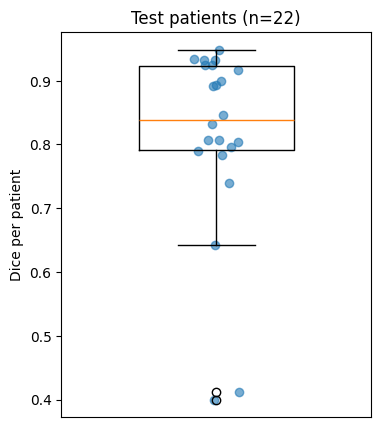

In [22]:
# Bootstrap confidence interval + boxplot of per-patient Dice
import matplotlib.pyplot as plt

d = np.array(list(scores.values()))
rng = np.random.default_rng(0)
boot = [rng.choice(d, len(d), replace=True).mean() for _ in range(1000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Mean Dice {d.mean():.3f}  (95% bootstrap CI {lo:.3f} to {hi:.3f}, n={len(d)} patients)")

fig, ax = plt.subplots(figsize=(4, 5))
ax.boxplot(d, widths=0.5)
ax.scatter(np.ones(len(d)) + rng.normal(0, 0.04, len(d)), d, alpha=0.6)
ax.set_ylabel("Dice per patient"); ax.set_xticks([]); ax.set_title(f"Test patients (n={len(d)})")
plt.savefig("/kaggle/working/dice_boxplot.png", dpi=150, bbox_inches="tight")

TCGA_DU_5852_19950709: Dice 0.40, tumor slices 8, total tumor pixels 5083, predicted pixels 19155


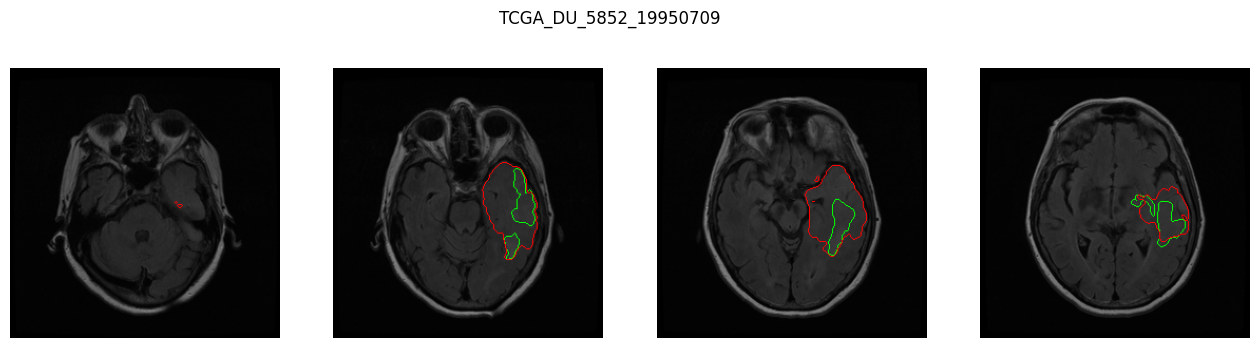

TCGA_FG_6692_20020606: Dice 0.41, tumor slices 7, total tumor pixels 7115, predicted pixels 21969


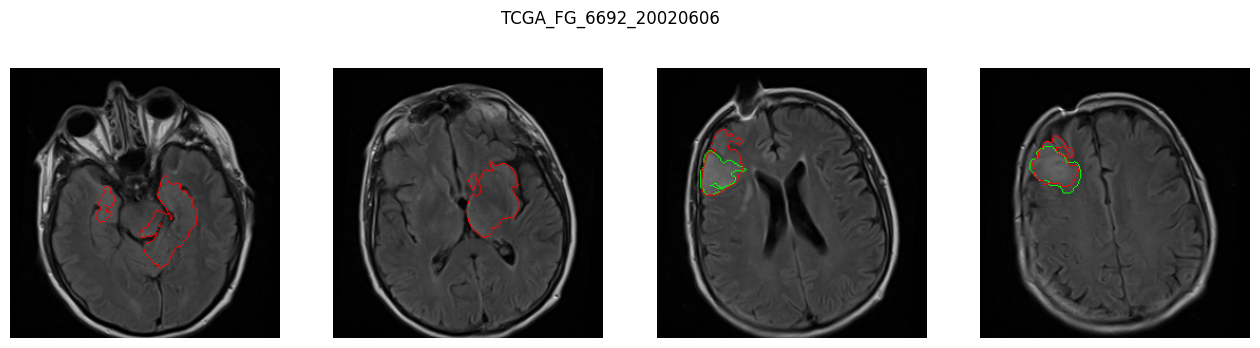

TCGA_HT_7602_19951103: Dice 0.64, tumor slices 7, total tumor pixels 6946, predicted pixels 13607


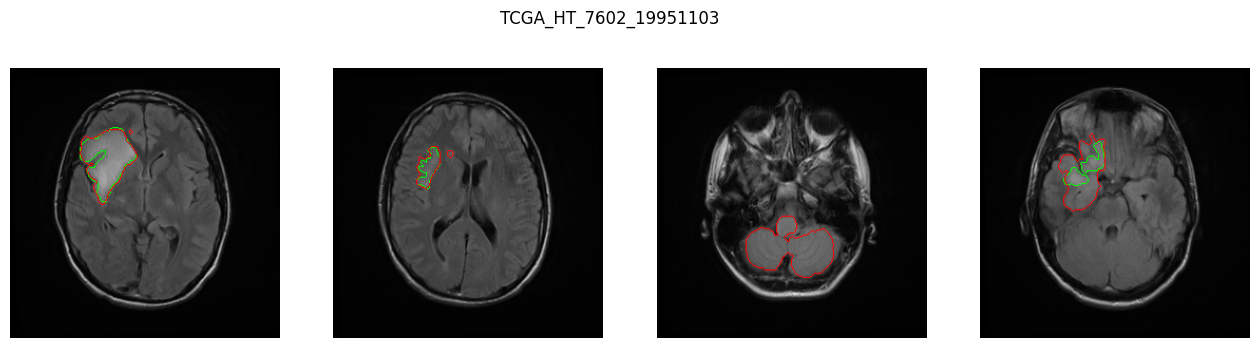

In [23]:
# Failure analysis on the 3 worst test patients (green = ground truth, red = model)
from skimage.segmentation import find_boundaries

worst = [p for p, _ in sorted(scores.items(), key=lambda x: x[1])[:3]]
for pid in worst:
    ii = [i for i in np.where(pt == pid)[0] if gt[i].sum() > 0 or pred[i].sum() > 0]
    sizes = gt[pt == pid].sum(axis=(1, 2))
    print(f"{pid}: Dice {scores[pid]:.2f}, tumor slices {(sizes > 0).sum()}, "
          f"total tumor pixels {sizes.sum()}, predicted pixels {pred[pt == pid].sum()}")
    ii = ii[::max(1, len(ii) // 4)][:4]
    fig, ax = plt.subplots(1, len(ii), figsize=(4 * len(ii), 4))
    for a, i in zip(np.atleast_1d(ax), ii):
        im = np.stack([X[test_idx[i]][..., 1]] * 3, -1).astype(np.uint8)
        im[find_boundaries(gt[i], mode="outer")] = [0, 255, 0]
        im[find_boundaries(pred[i], mode="outer")] = [255, 0, 0]
        a.imshow(im); a.axis("off")
    plt.suptitle(pid); plt.show()

In [24]:
# Post-processing: remove tiny predicted blobs. Tune min_area on VALIDATION, not test.
from skimage.morphology import remove_small_objects

def clean(p, min_area):
    return np.stack([remove_small_objects(s, min_area) if s.any() else s for s in p])

def summarize(p, g, ptn):
    sc = np.array([dice(p[ptn == q], g[ptn == q]) for q in np.unique(ptn)])
    e = g.sum(axis=(1, 2)) == 0
    return sc.mean(), np.median(sc), int((p[e].sum(axis=(1, 2)) > 0).sum()), int(e.sum())

pred_val, gt_val, pt_val = predict(val_idx), Y[val_idx], patients[val_idx]
for a in [0, 25, 50, 100, 200]:
    m, md, fa_, n = summarize(clean(pred_val, a), gt_val, pt_val)
    print(f"min_area {a:3d}: val mean Dice {m:.3f}, false alarms {fa_}/{n}")

min_area   0: val mean Dice 0.861, false alarms 5/269
min_area  25: val mean Dice 0.861, false alarms 4/269
min_area  50: val mean Dice 0.862, false alarms 3/269
min_area 100: val mean Dice 0.862, false alarms 3/269
min_area 200: val mean Dice 0.864, false alarms 1/269


In [25]:
# Run ONCE, using the min_area with the best validation Dice (200 in the table above)
best_area = 200
m, md, fa_, n = summarize(clean(pred, best_area), gt, pt)
print(f"U-Net + post-processing (min_area={best_area}): mean {m:.3f}, median {md:.3f}, false alarms {fa_}/{n}")
log_result(f"U-Net + post-processing (min_area={best_area})", m, md, fa_, n)

# final results table for the README
!pip install -q tabulate
import pandas as pd
print(pd.read_csv("/kaggle/working/results.csv").to_markdown(index=False))

In [28]:

import os, numpy as np, torch, gradio as gr
import segmentation_models_pytorch as smp
from skimage.io import imread
from skimage.segmentation import find_boundaries

device = "cuda" if torch.cuda.is_available() else "cpu"
WEIGHTS = "best_unet.pt"          # in Kaggle use "/kaggle/working/best_unet.pt"

model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(torch.load(WEIGHTS, map_location=device, weights_only=True))
model.to(device).eval()

def segment(path):
    if "_mask" in os.path.basename(path):
        return np.zeros((256, 256, 3), np.uint8), "That is a mask file. Upload the MRI image instead (no '_mask' in the name)."
    raw = imread(path)
    if raw.max() == 0:
        return np.zeros((256, 256, 3), np.uint8), "Blank image, please upload an MRI slice."
    if raw.ndim == 2:
        raw = np.stack([raw] * 3, -1)
    img = raw[..., :3].astype(np.float32)
    flair = img[..., 1].copy()                     # shown to the user, before normalizing
    note = ""
    if flair.max() == 0:                           # FLAIR missing: show the brightest other channel
        alt = 0 if img[..., 0].mean() >= img[..., 2].mean() else 2
        flair = img[..., alt].copy()
        note = " (FLAIR channel missing in this slice, so the prediction may be less reliable)"

    for c in range(3):                             # same normalization as training
        ch = img[..., c]
        brain = ch[ch > 0]
        if brain.size:
            img[..., c] = np.where(ch > 0, (ch - brain.mean()) / (brain.std() + 1e-8), 0)

    with torch.no_grad():
        x = torch.from_numpy(img).permute(2, 0, 1)[None].to(device)
        mask = (torch.sigmoid(model(x)) > 0.5)[0, 0].cpu().numpy()

    base = (255 * (flair - flair.min()) / (np.ptp(flair) + 1e-8)).astype(np.uint8)
    out = np.stack([base] * 3, -1)
    out[find_boundaries(mask, mode="outer")] = [255, 0, 0]       # red outline
    area = int(mask.sum())
    return out, (f"Tumor area: {area} pixels{note}" if area else f"No tumor detected{note}")

demo = gr.Interface(
    fn=segment,
    inputs=gr.File(label="Upload an MRI slice (3-channel .tif/.png)", type="filepath"),
    outputs=[gr.Image(label="Tumor outline"), gr.Textbox(label="Result")],
    title="Brain tumor segmentation (U-Net)",
    description="Research demo on the LGG MRI dataset. Not a medical device.",
    examples=[[f"samples/{f}"] for f in sorted(os.listdir("samples")) if f.endswith(".tif")]
             if os.path.isdir("samples") else None,
)

if __name__ == "__main__":
    demo.launch()                  # add share=True when running in Kaggle

* Running on local URL:  http://127.0.0.1:7860
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://f09631ac36ff9f508d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_11.tif 
 Tumor area: 1377 pixels


(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

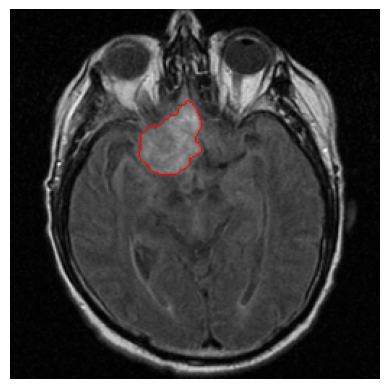

In [29]:
import glob, matplotlib.pyplot as plt
from skimage.io import imread

ROOT = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
masks = sorted(glob.glob(f"{ROOT}/*/*_mask.tif"))
big = [m for m in masks if imread(m).sum() > 500 * 255]      # slices with a visible tumor
p = big[0].replace("_mask", "")

out, txt = segment(p)
print(p, "\n", txt)
plt.imshow(out); plt.axis("off")

In [31]:
import shutil, os
os.makedirs("/kaggle/working/samples", exist_ok=True)

# 6 test slices with a visible tumor (largest masks give clear demos)
has_tumor = [i for i in range(len(test_idx)) if gt[i].sum() > 500]
for i in has_tumor[::max(1, len(has_tumor)//6)][:6]:
    shutil.copy(images[test_idx[i]], "/kaggle/working/samples/")

shutil.make_archive("/kaggle/working/samples", "zip", "/kaggle/working/samples")
print(os.listdir("/kaggle/working/samples"))

['TCGA_DU_6407_19860514_20.tif', 'TCGA_HT_7882_19970125_15.tif', 'TCGA_FG_7637_20000922_16.tif', 'TCGA_HT_7605_19950916_28.tif', 'TCGA_DU_7306_19930512_18.tif', 'TCGA_CS_4941_19960909_11.tif']
